In [1]:
# ============================================================================
# CELDA 1: IMPORTACIONES Y CONFIGURACIÓN
# ============================================================================

import os
import sys
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NOTEBOOK_DIR = os.getcwd()
PROJECT_ROOT = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

from core.parameters import SystemParameters, OptimizationParameters
from core.data_loader import SystemData
from core.system_cache import SystemCache
from core.power_flow import power_flow_hourly_optimized
from analysis.loaders import cargar_y_calcular_resultados
from analysis.economics import evaluacion_economica
from analysis.emissions import analisis_emisiones

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 20

print("Módulos importados correctamente")

Módulos importados correctamente


In [2]:
# ============================================================================
# CELDA 2: SELECCIÓN DE ALGORITMO, SISTEMA Y MEJOR EJECUCIÓN
# ============================================================================

ALGORITMO = 'PSOWOA' # 'PSO', 'WOA', 'WOAPSO', 'PSOWOA', 'GA'
SISTEMA = 'IEEE33' # 'IEEE33' o 'IEEE69'

OPT_DIR = os.path.join(PROJECT_ROOT, 'outputs', 'optimizacion', ALGORITMO, SISTEMA)
os.makedirs(OPT_DIR, exist_ok=True)

# Listar archivos de ejecución disponibles
patron_ejecuciones = os.path.join(OPT_DIR, f'Ejecucion_*_{ALGORITMO}_{SISTEMA}.xlsx')
lista_ejecuciones = sorted(glob.glob(patron_ejecuciones))
print(f"Archivos de ejecución encontrados: {len(lista_ejecuciones)}")

# Buscar la mejor ejecución según resumen
resumen_global_file = os.path.join(OPT_DIR, f'Resumen_{ALGORITMO}_{SISTEMA}.xlsx')
mejor_ejecucion = None
if os.path.exists(resumen_global_file):
    df_res = pd.read_excel(resumen_global_file)
    idx_min = df_res['Funcion_Objetivo'].idxmin()
    mejor_ejecucion = int(df_res.loc[idx_min, 'Ejecucion'])
    print(f"Mejor ejecución según resumen: {mejor_ejecucion}")

# Seleccionar el archivo de ejecución adecuado
excel_file = None
if mejor_ejecucion is not None:
    candidato = os.path.join(OPT_DIR, f'Ejecucion_{mejor_ejecucion}_{ALGORITMO}_{SISTEMA}.xlsx')
    if os.path.exists(candidato):
        excel_file = candidato
        print(f"Usando archivo de mejor ejecución: {os.path.basename(candidato)}")
    else:
        print(f"⚠ El archivo de la mejor ejecución {mejor_ejecucion} no existe. Se usará el primero disponible.")

if excel_file is None and lista_ejecuciones:
    excel_file = lista_ejecuciones[0]
    print(f"Usando archivo de ejecución: {os.path.basename(excel_file)}")

if excel_file is None:
    raise FileNotFoundError(f"No se encontraron archivos de ejecución en {OPT_DIR}")

print(f"\nArchivo Excel seleccionado: {excel_file}")


Archivos de ejecución encontrados: 100
Mejor ejecución según resumen: 45
Usando archivo de mejor ejecución: Ejecucion_45_PSOWOA_IEEE33.xlsx

Archivo Excel seleccionado: G:\Mi unidad\TESIS\CODIGO\codigo\proyecto\outputs\optimizacion\PSOWOA\IEEE33\Ejecucion_45_PSOWOA_IEEE33.xlsx


In [3]:
# ============================================================================
# CELDA 3: DIAGNÓSTICO DEL ARCHIVO EXCEL (HOJAS Y COLUMNAS)
# ============================================================================

print("\nDiagnóstico del archivo Excel:")
try:
    xls = pd.ExcelFile(excel_file)
    print(f"Hojas disponibles: {xls.sheet_names}")
    if 'Estado_BC_Horario' in xls.sheet_names:
        df_estado = pd.read_excel(excel_file, sheet_name='Estado_BC_Horario')
        print(f"Columnas en 'Estado_BC_Horario': {list(df_estado.columns)}")
        print(f"Primeras 3 filas:")
        print(df_estado.head(3).to_string())
    else:
        print("No se encontró la hoja 'Estado_BC_Horario'")
except Exception as e:
    print(f"Error al leer Excel: {e}")


Diagnóstico del archivo Excel:
Hojas disponibles: ['Demanda_Horaria', 'Voltajes_Iniciales', 'Perdidas_Activas_Iniciales', 'Perdidas_Reactivas_Iniciales', 'Costos_Iniciales', 'Soluciones_Iteraciones', 'Estadisticas_Iteraciones', 'Voltajes_Finales', 'Perdidas_Activas_Finales', 'Perdidas_Reactivas_Finales', 'Estado_BC_Horario', 'Costos_Detallados', 'Resumen']
Columnas en 'Estado_BC_Horario': ['Hora', 'BC_Barra_31', 'BC_Barra_28', 'BC_Barra_16']
Primeras 3 filas:
   Hora  BC_Barra_31  BC_Barra_28  BC_Barra_16
0     0            1            0            0
1     1            1            0            0
2     2            1            0            0


In [4]:
# ============================================================================
# CELDA 4: LEER CONFIGURACIÓN DE LA SOLUCIÓN DESDE HOJA 'Resumen'
# ============================================================================

def extraer_lista_int(valor):
    """
    Convierte el valor de una celda en una lista de enteros.
    Acepta string con números separados por espacios o un solo número.
    """
    if pd.isna(valor):
        return []
    if isinstance(valor, str):
        if valor.strip() == '':
            return []
        return [int(float(x)) for x in valor.split()]  # float->int para admitir decimales
    elif isinstance(valor, (int, float, np.integer, np.floating)):
        return [int(valor)] if int(valor) > 0 else [0]
    else:
        return []


def extraer_lista_float(valor):
    """
    Convierte el valor de una celda en una lista de flotantes.
    Acepta string con números separados por espacios o un solo número.
    """
    if pd.isna(valor):
        return []
    if isinstance(valor, str):
        if valor.strip() == '':
            return []
        return [float(x) for x in valor.split()]
    elif isinstance(valor, (int, float, np.integer, np.floating)):
        return [float(valor)] if float(valor) > 0 else [0.0]
    else:
        return []


df_ejec = pd.read_excel(excel_file, sheet_name='Resumen')
best_solution = df_ejec.iloc[0]

# Extraer listas (manejan tanto string como número)
pv_barras = extraer_lista_int(best_solution['Barras_PV'])
pv_caps = extraer_lista_float(best_solution['Capacidades_PV_kW'])
bc_barras = extraer_lista_int(best_solution['Barras_BC'])
bc_caps = extraer_lista_float(best_solution['Capacidades_BC_kVAR'])

# Rellenar hasta 4 elementos con ceros
while len(pv_barras) < 4:
    pv_barras.append(0)
while len(pv_caps) < 4:
    pv_caps.append(0.0)
while len(bc_barras) < 4:
    bc_barras.append(0)
while len(bc_caps) < 4:
    bc_caps.append(0.0)

print("Configuración de la solución:")
print(f"PV: barras={pv_barras}, capacidades={pv_caps}")
print(f"BC: barras={bc_barras}, capacidades={bc_caps}")


Configuración de la solución:
PV: barras=[6, 7, 15, 17], capacidades=[2209.77, 50.0, 267.77, 50.0]
BC: barras=[31, 28, 16, 0], capacidades=[282.28, 614.09, 443.14, 0.0]


In [5]:
# ============================================================================
# CELDA 5: CARGAR RESULTADOS Y EJECUTAR FLUJOS
# ============================================================================

ruta_excel_estado_bc = excel_file

datos_analisis = cargar_y_calcular_resultados(
    capacidad_bc1=bc_caps[0], ubicacion_bc1=bc_barras[0],
    capacidad_bc2=bc_caps[1], ubicacion_bc2=bc_barras[1],
    capacidad_bc3=bc_caps[2], ubicacion_bc3=bc_barras[2],
    capacidad_bc4=bc_caps[3], ubicacion_bc4=bc_barras[3],
    capacidad_pv1=pv_caps[0], ubicacion_pv1=pv_barras[0],
    capacidad_pv2=pv_caps[1], ubicacion_pv2=pv_barras[1],
    capacidad_pv3=pv_caps[2], ubicacion_pv3=pv_barras[2],
    capacidad_pv4=pv_caps[3], ubicacion_pv4=pv_barras[3],
    ruta_excel_estado_bc=ruta_excel_estado_bc,
    sistema=SISTEMA
)

print("Datos cargados correctamente")

OUTPUT_ANALYSIS = os.path.join(PROJECT_ROOT, 'outputs', 'analisis', ALGORITMO, SISTEMA)
os.makedirs(OUTPUT_ANALYSIS, exist_ok=True)
ruta_modelos = OUTPUT_ANALYSIS

POST-PROCESAMIENTO - ANÁLISIS DE SOLUCIÓN - IEEE33
Número de barras: 33
Número de líneas: 32

Cargando estado de BC desde Excel...
Estados de BC cargados para barras: [31, 28, 16]

Configuración cargada:
  PV: Barras [6, 7, 15, 17]
      Capacidades [2209.77, 50.0, 267.77, 50.0] kW
  BC: Barras [31, 28, 16, 0]
      Capacidades [282.28, 614.09, 443.14, 0.0] kVAR

Ejecutando flujos de potencia horarios...
✓ Cálculos completados
Datos cargados correctamente


Generando gráfico de voltajes...


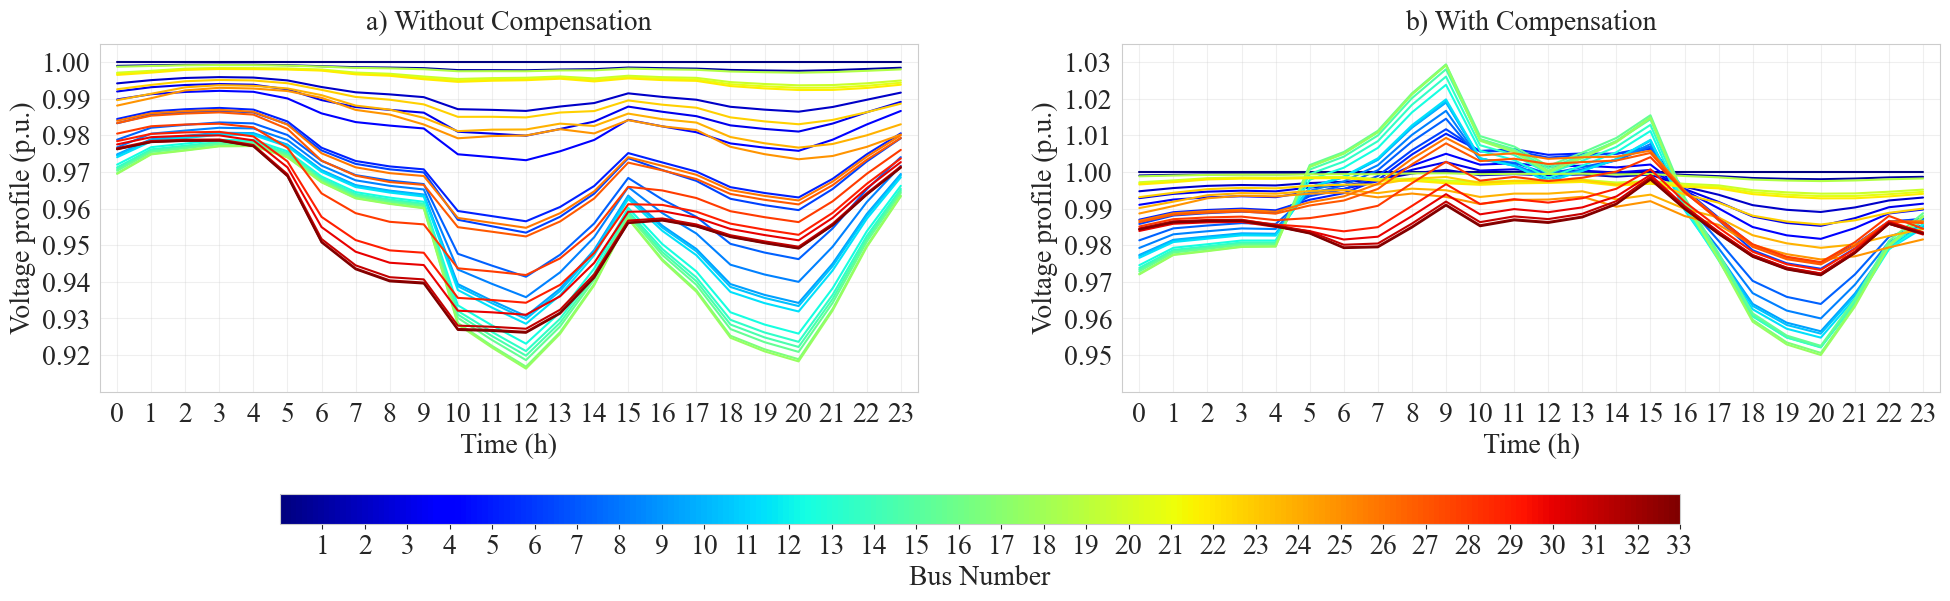

✓ Gráfico de voltajes completado


In [6]:
# ============================================================================
# CELDA 6: PERFILES DE VOLTAJE
# ============================================================================

print("Generando gráfico de voltajes...")

system_data = datos_analisis['system_data']
resultados_sin = datos_analisis['resultados_sin']
resultados_con = datos_analisis['resultados_con']

nbus = system_data.nbus
colores = plt.cm.jet(np.linspace(0, 1, nbus))
horas_plot = range(0, 24)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6))

# Sin compensación
for i in range(nbus):
    voltajes = [np.abs(resultados_sin[h]['Vm'][i]) for h in range(24)]
    ax1.plot(horas_plot, voltajes, color=colores[i], linewidth=1.5)
ax1.set_xlabel('Time (h)', fontsize=20)
ax1.set_ylabel('Voltage profile (p.u.)', fontsize=20)
ax1.set_title('a) Without Compensation', fontsize=20, pad=10)
ax1.set_xlim(-0.5, 23.5)
ax1.set_ylim(0.91, 1.005)
ax1.set_xticks(range(0, 24, 1))
ax1.set_yticks(np.arange(0.92, 1.005, 0.01))
ax1.grid(True, alpha=0.3)
ax1.tick_params(axis='both', labelsize=20)

# Con compensación
for i in range(nbus):
    voltajes = [np.abs(resultados_con[h]['Vm'][i]) for h in range(24)]
    ax2.plot(horas_plot, voltajes, color=colores[i], linewidth=1.5)
ax2.set_xlabel('Time (h)', fontsize=20)
ax2.set_ylabel('Voltage profile (p.u.)', fontsize=20)
ax2.set_title('b) With Compensation', fontsize=20, pad=10)
ax2.set_xlim(-0.5, 23.5)
ax2.set_ylim(0.94, 1.035)
ax2.set_xticks(range(0, 24, 1))
ax2.set_yticks(np.arange(0.95, 1.035, 0.01))
ax2.grid(True, alpha=0.3)
ax2.tick_params(axis='both', labelsize=20)

# Colorbar horizontal
plt.subplots_adjust(left=0.06, right=0.98, top=0.88, bottom=0.30, wspace=0.25)
cbar_ax = fig.add_axes([0.15, 0.08, 0.7, 0.05])
sm = plt.cm.ScalarMappable(cmap=plt.cm.jet, norm=plt.Normalize(vmin=0, vmax=nbus))
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Bus Number', fontsize=20)
etiquetas_colorbar = list(range(1, nbus + 1, max(1, nbus // 20)))
cbar.set_ticks(etiquetas_colorbar)
cbar.set_ticklabels([str(x) for x in etiquetas_colorbar])
cbar.ax.tick_params(labelsize=20)

nombre_archivo = "Voltage_Profile33.png"
ruta_completa = os.path.join(ruta_modelos, nombre_archivo)
plt.savefig(ruta_completa, dpi=600, bbox_inches='tight')
plt.savefig(os.path.splitext(ruta_completa)[0] + '.svg')
plt.show()
print("✓ Gráfico de voltajes completado")

In [7]:
# ============================================================================
# CELDA 7: ANÁLISIS BREVE DE PERFILES DE VOLTAJE
# ============================================================================

print("\nANÁLISIS DE PERFILES DE VOLTAJE")
print("=" * 70)

voltajes_sin_todos = []
voltajes_con_todos = []
for h in range(24):
    for i in range(nbus):
        voltajes_sin_todos.append({'hora': h, 'bus': i + 1, 'voltaje': np.abs(resultados_sin[h]['Vm'][i])})
        voltajes_con_todos.append({'hora': h, 'bus': i + 1, 'voltaje': np.abs(resultados_con[h]['Vm'][i])})

v_min_sin = min(voltajes_sin_todos, key=lambda x: x['voltaje'])
v_max_sin = max(voltajes_sin_todos, key=lambda x: x['voltaje'])
v_min_con = min(voltajes_con_todos, key=lambda x: x['voltaje'])
v_max_con = max(voltajes_con_todos, key=lambda x: x['voltaje'])

print(
    f"SIN COMPENSACIÓN: min={v_min_sin['voltaje']:.4f} pu (bus {v_min_sin['bus']}, h {v_min_sin['hora']}), max={v_max_sin['voltaje']:.4f} pu (bus {v_max_sin['bus']}, h {v_max_sin['hora']})")
print(
    f"CON COMPENSACIÓN: min={v_min_con['voltaje']:.4f} pu (bus {v_min_con['bus']}, h {v_min_con['hora']}), max={v_max_con['voltaje']:.4f} pu (bus {v_max_con['bus']}, h {v_max_con['hora']})")

mejora_min = v_min_con['voltaje'] - v_min_sin['voltaje']
mejora_max = v_max_con['voltaje'] - v_max_sin['voltaje']
rango_sin = v_max_sin['voltaje'] - v_min_sin['voltaje']
rango_con = v_max_con['voltaje'] - v_min_con['voltaje']
print(f"Mejora voltaje mínimo: {mejora_min:.4f} pu ({mejora_min * 100:.2f}%)")
print(f"Variación voltaje máximo: {mejora_max:+.4f} pu ({mejora_max * 100:+.2f}%)")
print(f"Reducción rango: {rango_sin:.4f} -> {rango_con:.4f} pu")


ANÁLISIS DE PERFILES DE VOLTAJE
SIN COMPENSACIÓN: min=0.9163 pu (bus 18, h 12), max=1.0000 pu (bus 1, h 0)
CON COMPENSACIÓN: min=0.9500 pu (bus 18, h 20), max=1.0294 pu (bus 16, h 9)
Mejora voltaje mínimo: 0.0337 pu (3.37%)
Variación voltaje máximo: +0.0294 pu (+2.94%)
Reducción rango: 0.0837 -> 0.0793 pu



Generando gráfico de pérdidas activas...


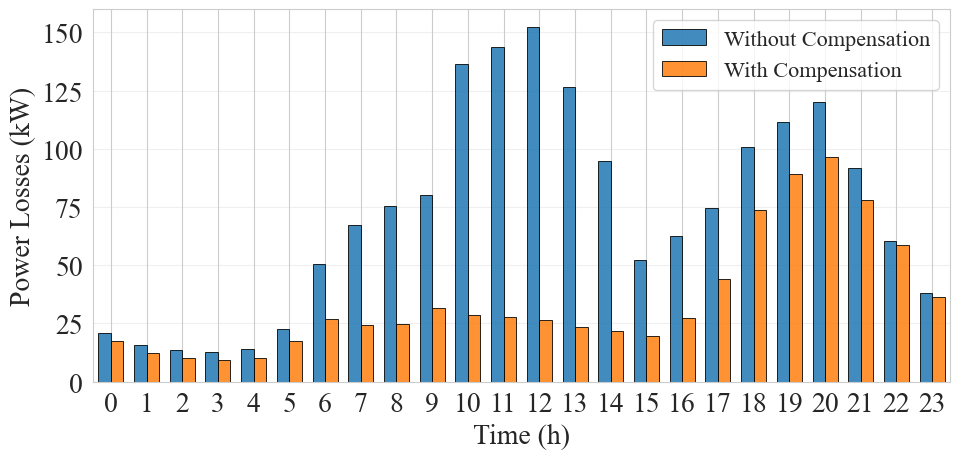

Pérdidas totales sin compensación: 1738.32 kW
Pérdidas totales con compensación: 835.86 kW
Reducción: 902.46 kW (51.92%)


In [8]:
# ============================================================================
# CELDA 8: PÉRDIDAS ACTIVAS
# ============================================================================

print("\nGenerando gráfico de pérdidas activas...")

fig, ax = plt.subplots(figsize=(10, 5))

p_sin = [res['PTloss'] for res in resultados_sin]
p_con = [res['PTloss'] for res in resultados_con]

horas_plot = np.arange(24)
ancho = 0.35
pos1 = horas_plot - ancho / 2
pos2 = horas_plot + ancho / 2

ax.bar(pos1, p_sin, ancho, label='Without Compensation', color='#1f77b4', alpha=0.85, edgecolor='black', linewidth=0.7)
ax.bar(pos2, p_con, ancho, label='With Compensation', color='#ff7f0e', alpha=0.85, edgecolor='black', linewidth=0.7)

ax.set_xlabel('Time (h)', fontsize=20)
ax.set_ylabel('Power Losses (kW)', fontsize=20)
ax.legend(fontsize=16, loc='best')
ax.grid(True, alpha=0.3, axis='y')
ax.set_xlim(-0.5, 23.5)
ax.set_xticks(range(0, 24, 1))
ax.tick_params(axis='both', labelsize=20)
ax.set_ylim(0, 160)
ax.set_yticks(np.arange(0, 160, 25))
plt.tight_layout()

nombre_archivo = "perdidas_33.png"
ruta_completa = os.path.join(ruta_modelos, nombre_archivo)
plt.savefig(ruta_completa, dpi=600, bbox_inches='tight')
plt.savefig(os.path.splitext(ruta_completa)[0] + '.svg')
plt.show()

perdidas_sin_total = sum(p_sin)
perdidas_con_total = sum(p_con)
reduccion_total = perdidas_sin_total - perdidas_con_total
porcentaje_reduccion = (reduccion_total / perdidas_sin_total) * 100
print(f"Pérdidas totales sin compensación: {perdidas_sin_total:.2f} kW")
print(f"Pérdidas totales con compensación: {perdidas_con_total:.2f} kW")
print(f"Reducción: {reduccion_total:.2f} kW ({porcentaje_reduccion:.2f}%)")


Generando gráfico de estado de BC...


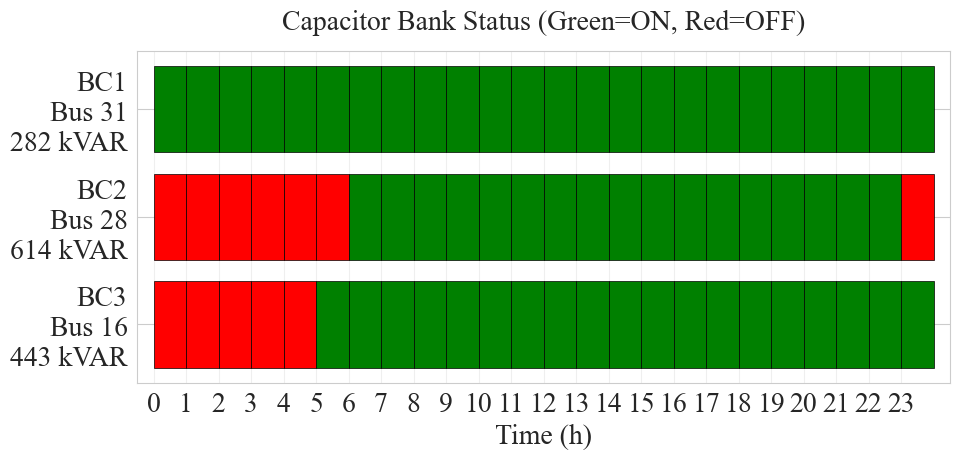

Total BC: 3, Capacidad total: 1339.51 kVAR
BC3 (Bus 16): 19/24 horas ON
BC2 (Bus 28): 17/24 horas ON
BC1 (Bus 31): 24/24 horas ON


In [9]:
# ============================================================================
# CELDA 9: ESTADO DE BANCOS DE CONDENSADORES
# ============================================================================

print("\nGenerando gráfico de estado de BC...")

estado_bc_por_barra = datos_analisis['estado_bc']
bc_config = datos_analisis['bc_config']

nombres = bc_config['nombres']
ubicaciones = bc_config['ubicaciones']
capacidades = bc_config['capacidades']

bc_existentes = []
for i, nombre in enumerate(nombres):
    if capacidades[i] > 0 and ubicaciones[i] in estado_bc_por_barra:
        bc_existentes.append({
            'nombre': nombre,
            'ubicacion': ubicaciones[i],
            'capacidad': capacidades[i],
            'estados': estado_bc_por_barra[ubicaciones[i]]
        })

if not bc_existentes:
    print("⚠ No se encontraron BC con estado disponible. Revise las columnas de 'Estado_BC_Horario'.")
else:
    bc_existentes.reverse()
    fig, ax = plt.subplots(figsize=(10, 5))
    for idx, bc in enumerate(bc_existentes):
        for hora in range(24):
            color = 'green' if bc['estados'][hora] == 1 else 'red'
            ax.barh(idx, 1, left=hora, height=0.8,
                    color=color, edgecolor='black', linewidth=0.5)

    ax.set_yticks(range(len(bc_existentes)))
    ax.set_yticklabels([f"{bc['nombre']}\nBus {bc['ubicacion']}\n{bc['capacidad']:.0f} kVAR"
                        for bc in bc_existentes], fontsize=10)
    ax.set_xlabel('Time (h)', fontsize=20)
    ax.set_ylabel('')
    ax.set_title('Capacitor Bank Status (Green=ON, Red=OFF)', fontsize=20, pad=15)
    ax.set_xlim(-0.5, 24.5)
    ax.set_xticks(range(24))
    ax.grid(True, axis='x', alpha=0.3)
    ax.tick_params(axis='both', labelsize=20)
    plt.tight_layout()

    nombre_archivo = "Capacitor_Status_33.png"
    ruta_completa = os.path.join(ruta_modelos, nombre_archivo)
    plt.savefig(ruta_completa, dpi=600)
    plt.savefig(os.path.splitext(ruta_completa)[0] + '.svg')
    plt.show()

    capacidad_total = sum(bc['capacidad'] for bc in bc_existentes)
    print(f"Total BC: {len(bc_existentes)}, Capacidad total: {capacidad_total:.2f} kVAR")
    for bc in bc_existentes:
        horas_on = sum(bc['estados'])
        print(f"{bc['nombre']} (Bus {bc['ubicacion']}): {horas_on}/24 horas ON")

In [10]:
# ============================================================================
# CELDA 10: EVALUACIÓN ECONÓMICA
# ============================================================================

print("\nEjecutando evaluación económica...")
resultado_economico = evaluacion_economica(datos_analisis, tasa_descuento=0.08,
                                           horizonte=20, vida_util_pv=20, vida_util_bc=10)

df_eco = pd.DataFrame([resultado_economico])
df_eco.to_csv(os.path.join(OUTPUT_ANALYSIS, 'evaluacion_economica.csv'), index=False)
print("Evaluación económica guardada en CSV")


Ejecutando evaluación económica...

TABLA DE INGRESOS (AHORROS) ANUALES
Ahorro en compra de energía: $858,018.69
Ahorro por reducción de pérdidas: $55,011.23
TOTAL INGRESOS ANUALES: $913,029.93
Valor residual PV: $0.00
Valor residual BC: $0.00

TABLA DE EGRESOS
CAPEX PV: $12,839,371.12
CAPEX BC: $38,287.75
O&M PV anual: $108,231.93
O&M BC anual: $900.00
Reemplazos BC en años: [10]

INDICADORES ECONÓMICOS
Payback: 16.02 años
ROI: 24.55%
VPN: $-5,002,604.48
Evaluación económica guardada en CSV


In [11]:
# ============================================================================
# CELDA 11: ANÁLISIS DE EMISIONES
# ============================================================================

print("\nEjecutando análisis de emisiones...")
resultado_emisiones = analisis_emisiones(datos_analisis)

df_emisiones = pd.DataFrame({
    'Contaminante': ['NOx', 'SO2', 'CO2'],
    'Base_lb': [resultado_emisiones['emisiones_base']['NOx'],
                resultado_emisiones['emisiones_base']['SO2'],
                resultado_emisiones['emisiones_base']['CO2']],
    'Proyecto_lb': [resultado_emisiones['emisiones_proy']['NOx'],
                    resultado_emisiones['emisiones_proy']['SO2'],
                    resultado_emisiones['emisiones_proy']['CO2']],
    'Reduccion_lb': [resultado_emisiones['reduccion']['NOx'],
                     resultado_emisiones['reduccion']['SO2'],
                     resultado_emisiones['reduccion']['CO2']]
})
df_emisiones.to_csv(os.path.join(OUTPUT_ANALYSIS, 'emisiones.csv'), index=False)
print("Emisiones guardadas en CSV")



Ejecutando análisis de emisiones...

ANÁLISIS DE EMISIONES CONTAMINANTES
Contaminante    Base (lb/año)        Proyecto (lb/año)    Reducción            % Reducción    
----------------------------------------------------------------------------------------------------
NOx             94,180.77            56,215.53            37,965.24            40.31          %
SO2             215,908.48           128,873.54           87,034.94            40.31          %
CO2             37,802,596.42        22,563,978.86        15,238,617.56        40.31          %

CO2 (ton/año): Base=17,146.99, Proyecto=10,234.86, Reducción=6,912.13
Emisiones guardadas en CSV
